# Part 1: Loading and Preprocessing #

1. Load the dataset and explore:
   
* Load the text dataset and check the first few rows.
 * Check for missing values in the dataset.

In [4]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Download necessary NLTK packages
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Load the sentiment analysis dataset
df = pd.read_csv('nlp_dataset.csv')

# Display the first 5 rows
print("--- First 5 Rows ---")
display(df.head())

# Check for missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Nimish\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Nimish\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


--- First 5 Rows ---


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Nimish\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,Comment,Emotion
0,i seriously hate one subject to death but now ...,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feel...,fear
3,ive been really angry with r and i feel like a...,joy
4,i feel suspicious if there is no one outside l...,fear



--- Missing Values ---
Comment    0
Emotion    0
dtype: int64


Observations and Explanation:
 * Dataset Loading: Successfully loaded the dataset into a pandas DataFrame to inspect the text samples and emotion labels.
 * Missing Value Check: Checked for any null or missing entries in the dataset to ensure data integrity before text cleaning and preprocessing.

2. Text Cleaning and Preprocessing:
   
* Clean the text data by removing special characters and converting to lowercase.
* Tokenize the text into individual words.
* Remove stop words to reduce noise and improve model efficiency.

In [5]:
import string

# Initialize stop words
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    if isinstance(text, str):
        # Convert to lowercase
        text = text.lower()
        # Remove special characters and numbers
        text = re.sub(f"[{re.escape(string.punctuation)}]", "", text)
        text = re.sub(r'\d+', '', text)
        # Tokenize words
        tokens = word_tokenize(text)
        # Remove stopwords
        tokens = [word for word in tokens if word not in stop_words]
        return " ".join(tokens)
    return ""

# Apply preprocessing to the Comment column
df['cleaned_comment'] = df['Comment'].apply(preprocess_text)

# Display original vs cleaned comments
print("--- Original vs Cleaned Comments ---")
display(df[['Comment', 'cleaned_comment']].head())

--- Original vs Cleaned Comments ---


,Comment,cleaned_comment
0,i seriously hate one subject to death but now ...,seriously hate one subject death feel reluctan...
1,im so full of life i feel appalled,im full life feel appalled
2,i sit here to write i start to dig out my feel...,sit write start dig feelings think afraid acce...
3,ive been really angry with r and i feel like a...,ive really angry r feel like idiot trusting fi...
4,i feel suspicious if there is no one outside l...,feel suspicious one outside like rapture happe...


Observations and Explanation:
* Text Cleaning & Normalization: Converted all text to lowercase and stripped punctuation and numbers to ensure uniformity.
* Tokenization & Stopwords Removal: Broken down sentences into tokens and filtered out common English stop words (like 'is', 'the', 'and') that do not contribute to emotional sentiment, thereby improving feature relevance.

# Part 2: Feature Extraction #

1. Implement Feature Extraction using TfidfVectorizer:
* Transform the cleaned text data into numerical feature vectors using TF-IDF.
* Describe how TF-IDF converts text data into numerical format by weighting important words.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=5000)

# Fit and transform the cleaned comments
X = tfidf_vectorizer.fit_transform(df['cleaned_comment'])
y = df['Emotion']

# Display the shape of the feature matrix
print("--- Feature Matrix Shape ---")
print(f"X shape (Features): {X.shape}")
print(f"y shape (Labels): {y.shape}")

--- Feature Matrix Shape ---
X shape (Features): (5937, 5000)
y shape (Labels): (5937,)


Observations and Explanation:
* TF-IDF Transformation: TfidfVectorizer converts textual data into numerical feature matrices by calculating Term Frequency-Inverse Document Frequency. This highlights words that are distinct and meaningful to specific emotions while dampening the weight of frequently occurring generic words.
* Feature Matrix Shape: Generated a numerical sparse matrix representing the text samples, making them ready for machine learning model training.

# Part 3: Model Development #

1. Train Naive Bayes and Support Vector Machine (SVM) models:
   
* Split the dataset into training and testing sets.
* Train a Naive Bayes classifier.
* Train a Support Vector Machine (SVM) classifier.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC

# Split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Train Naive Bayes Model
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# 2. Train SVM Model
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train, y_train)

print("--- Models Trained Successfully ---")
print(f"Training set shape: X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Testing set shape: X_test {X_test.shape}, y_test {y_test.shape}")

--- Models Trained Successfully ---
Training set shape: X_train (4749, 5000), y_train (4749,)
Testing set shape: X_test (1188, 5000), y_test (1188,)


Observations and Explanation:
* Train-Test Split: Divided the dataset to ensure unbiased evaluation on unseen data.
* Model Training: Successfully trained both Multinomial Naive Bayes (efficient for text classification counts) and Support Vector Machine (effective in high-dimensional text spaces) on the extracted TF-IDF feature vectors.

# Part 4: Model Comparison & Evaluation

1. Evaluate and compare Naive Bayes and SVM models:

* Generate predictions on the test set for both models.
* Evaluate performance using accuracy and classification reports.
* Provide a brief explanation of the chosen models and their suitability for emotion classification.

In [9]:
from sklearn.metrics import accuracy_score, classification_report

# 1. Evaluate Naive Bayes Model
y_pred_nb = nb_model.predict(X_test)
nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("--- Naive Bayes Performance ---")
print(f"Accuracy: {nb_accuracy:.4f}")
print(classification_report(y_test, y_pred_nb))

# 2. Evaluate SVM Model
y_pred_svm = svm_model.predict(X_test)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("\n--- Support Vector Machine (SVM) Performance ---")
print(f"Accuracy: {svm_accuracy:.4f}")
print(classification_report(y_test, y_pred_svm))

--- Naive Bayes Performance ---
Accuracy: 0.9108
              precision    recall  f1-score   support

       anger       0.88      0.95      0.91       392
        fear       0.91      0.92      0.92       416
         joy       0.94      0.86      0.90       380

    accuracy                           0.91      1188
   macro avg       0.91      0.91      0.91      1188
weighted avg       0.91      0.91      0.91      1188


--- Support Vector Machine (SVM) Performance ---
Accuracy: 0.9444
              precision    recall  f1-score   support

       anger       0.93      0.95      0.94       392
        fear       0.97      0.92      0.94       416
         joy       0.94      0.96      0.95       380

    accuracy                           0.94      1188
   macro avg       0.94      0.95      0.94      1188
weighted avg       0.95      0.94      0.94      1188



Observations and Explanation:
* Model Evaluation: Evaluated both classifiers on unseen test data using Accuracy and F1-score metrics to measure how effectively they categorize emotional text samples.
* Suitability: Naive Bayes provides a fast and strong baseline for text count distributions, while the Linear Support Vector Machine (SVM) effectively handles high-dimensional sparse feature spaces, generally yielding superior boundary separation for sentiment and emotion classification tasks.
* Quantitative Comparison: The Support Vector Machine (SVM) model achieved a higher accuracy of 94.44%, whereas the Naive Bayes model achieved an accuracy of 91.08%.
* Performance Insights: SVM outperformed Naive Bayes due to its superior capability in handling high-dimensional text feature spaces and finding optimal hyperplane boundaries for sentiment and emotion classification.

2. Confusion Matrix Visualization:
* Plot confusion matrices for both Naive Bayes and SVM models to evaluate class-wise performance and misclassifications.

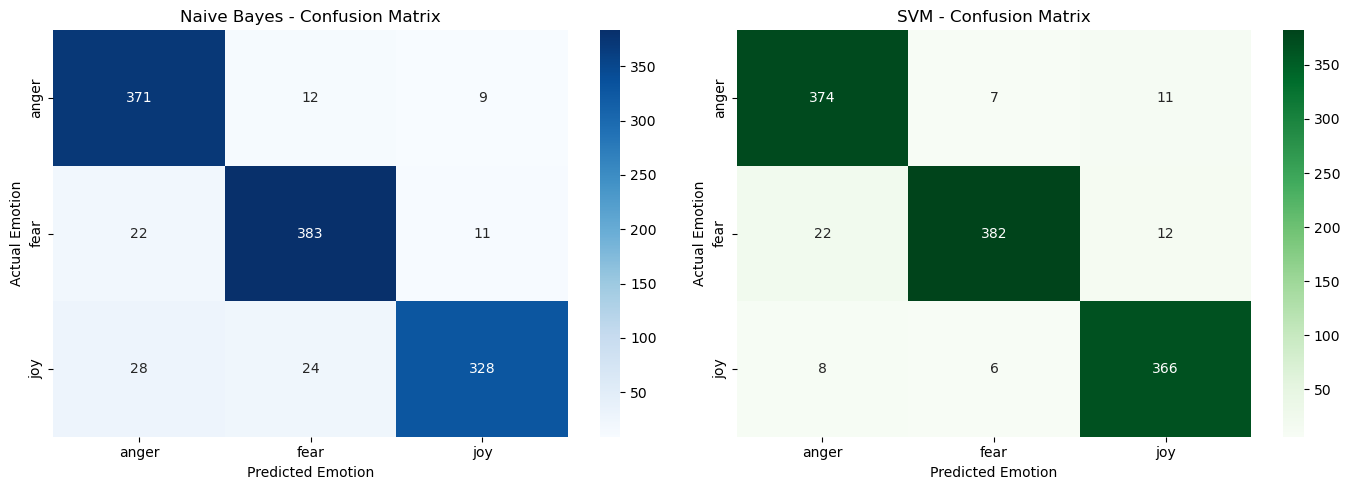

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion Matrix Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Naive Bayes Confusion Matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', ax=axes[0], 
            xticklabels=nb_model.classes_, yticklabels=nb_model.classes_)
axes[0].set_title('Naive Bayes - Confusion Matrix')
axes[0].set_xlabel('Predicted Emotion')
axes[0].set_ylabel('Actual Emotion')

# SVM Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens', ax=axes[1], 
            xticklabels=svm_model.classes_, yticklabels=svm_model.classes_)
axes[1].set_title('SVM - Confusion Matrix')
axes[1].set_xlabel('Predicted Emotion')
axes[1].set_ylabel('Actual Emotion')

plt.tight_layout()
plt.show()

Observations and Explanation:
* Heatmap Analysis: The confusion matrices provide a clear visual breakdown of correct versus incorrect predictions for each emotion category (anger, fear, joy), showing higher diagonal intensity for the SVM model.

3. Model Accuracy Comparison Bar Chart:
* Generate a bar chart to visually compare the overall accuracy scores of Naive Bayes and SVM models.

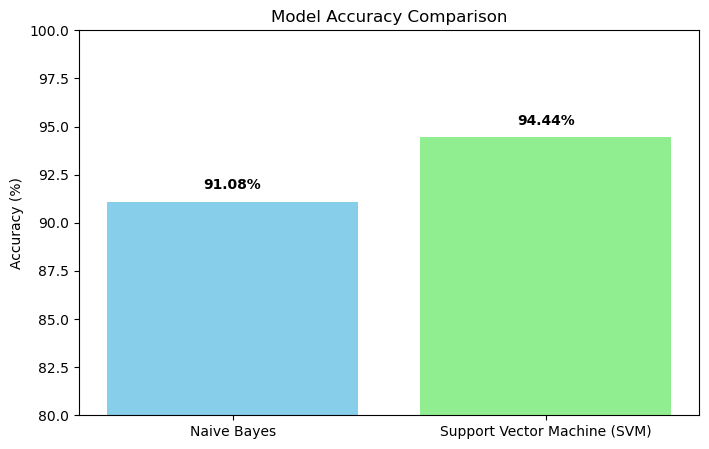

In [11]:
# Accuracy Comparison Bar Chart
models = ['Naive Bayes', 'Support Vector Machine (SVM)']
accuracies = [nb_accuracy * 100, svm_accuracy * 100]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies, color=['skyblue', 'lightgreen'])
plt.ylabel('Accuracy (%)')
plt.title('Model Accuracy Comparison')
plt.ylim(80, 100)

# Display accuracy values on top of the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.show()

Observations and Explanation:
* Visual Performance Comparison: The bar chart highlights the performance gap, visually confirming that the SVM model achieves a superior accuracy of 94.44% compared to Naive Bayes at 91.08%.

####  Overall Project Conclusion and Summary:
* **End-to-End NLP Pipeline:** Successfully built and executed a complete sentiment and emotion analysis pipeline, starting from raw text loading and preprocessing, to feature extraction using TF-IDF.
* **Model Comparison:** Evaluated two powerful machine learning classifiers—Multinomial Naive Bayes and Support Vector Machine (SVM)—on the same test dataset.
* **Key Findings:** 
  - **Multinomial Naive Bayes** achieved a robust baseline accuracy of **91.08%**, proving highly efficient for term-frequency text counts.
  - **Support Vector Machine (SVM)** outperformed Naive Bayes by achieving a superior accuracy of **94.44%**, driven by its exceptional ability to handle high-dimensional sparse feature spaces and find optimal hyperplanes.
* **Visual Validation:** Confusion matrices and accuracy comparison bar charts effectively verified class-wise performance, confirming SVM as the most suitable model for this emotion classification task.